In [36]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [37]:
class QuadState(TypedDict):

    a: int
    b: int 
    c: int

    equation: str
    discriminant: float
    result: str

In [38]:
def show_eqn(state: QuadState):

    eqn = f"{state['a']}x2 + {state['b']}x + {state['c']}"

    return {'equation': eqn}

def calc_disc(state: QuadState):

    disc = state['b']**2 - (4 * state['a'] * state['c'])

    return {'discriminant': disc}

In [39]:
def real_roots(state: QuadState):

    root_1 = (-state['b'] + state['discriminant'] ** 0.5) / (2 * state['a'])
    root_2 = (-state['b'] - state['discriminant'] ** 0.5) / (2 * state['a'])

    result = f'The roots are {root_1} and {root_2}'

    return {'result': result}

def repeated_roots(state: QuadState):

    root_1 = -state['b'] / (2 * state['a'])

    result = f'Only repeating root is {root_1}'

    return {'result': result}

def no_real_roots(state: QuadState):

    result = f'No real roots'

    return {'result': result}

def check_condition(state: QuadState) -> Literal['real_roots', 'no_real_roots', 'repeated_roots']:

    if state['discriminant'] > 0:
        return 'real_roots'
    elif state['discriminant'] == 0:
        return 'repeated_roots'
    else:
        return 'no_real_roots'

In [40]:
graph = StateGraph(QuadState)

graph.add_node('show_eqn', show_eqn)
graph.add_node('calc_disc', calc_disc)
graph.add_node('real_roots', real_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('no_real_roots', no_real_roots)

graph.add_edge(START, 'show_eqn')
graph.add_edge('show_eqn', 'calc_disc')
graph.add_conditional_edges('calc_disc', check_condition)

graph.add_edge('real_roots', END)
graph.add_edge('repeated_roots', END)
graph.add_edge('no_real_roots', END)

workflow = graph.compile()

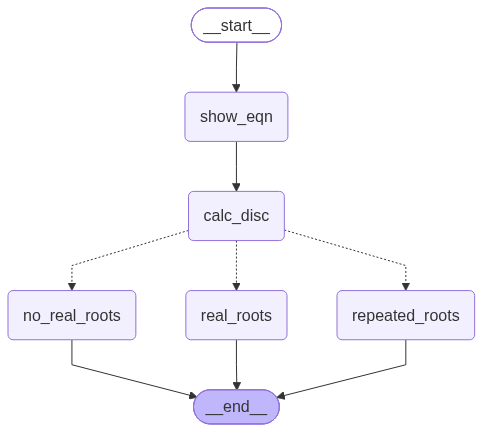

In [41]:
workflow

In [42]:
initial_state = {
    'a': 4,
    'b': -5,
    'c': -4
}

workflow.invoke(initial_state)

{'a': 4,
 'b': -5,
 'c': -4,
 'equation': '4x2 + -5x + -4',
 'discriminant': 89,
 'result': 'The roots are 1.8042476415070754 and -0.5542476415070754'}